<!-- P9 · Lucas : sections 0 à 3 (problème, import, doublons, exploration, split, prétraitement, ACP) -->
# Diabetes Health Indicators : dépistage du diabète

**Mini-projet Machine Learning — TAF MCE (IMT Atlantique)**

Même workflow que pour Spambase, avec les fonctions de `ml_workflow.py` :
1. import ; 2. nettoyage et prétraitement ; 3. séparation train / test ;
4. entraînement avec sélection de variables ; 5. validation.

## 0. Le problème et le choix de la métrique

Chaque ligne est un répondant de l'enquête téléphonique américaine BRFSS 2015 (CDC). La cible
`Diabetes_binary` vaut 1 pour un diabète ou un prédiabète déclaré. Les 21 variables sont des
indicateurs de santé et de mode de vie (tension, cholestérol, IMC, âge, revenu...).

L'usage naturel d'un tel modèle est le **dépistage** : repérer les personnes à orienter vers un test
sanguin. Les deux erreurs n'ont pas le même coût :
- un **faux négatif** est un diabète non détecté (complications évitables) ;
- un **faux positif** est un test sanguin inutile (coût faible).

On privilégie donc le **rappel**, sans laisser la précision s'effondrer. Le jeu est **déséquilibré**
(14 % de positifs), ce qui rend l'accuracy trompeuse. On retient :

| Rôle | Métrique |
|---|---|
| Comparer les modèles indépendamment du seuil | **AUC-PR** (average precision), plus informative que l'AUC-ROC quand les positifs sont rares ; AUC-ROC en complément |
| Choisir le seuil de décision | **F2** (rappel deux fois plus important que la précision) ou **risque bayésien** avec un coût $c_{FN} = 5\,c_{FP}$ |
| Lecture globale insensible au déséquilibre | accuracy équilibrée $= (\text{rappel} + \text{spécificité})/2$ |

In [1]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import ml_workflow as mw

SEED = 42
pd.set_option("display.precision", 4)
pd.set_option("display.width", 160)
plt.rcParams["figure.dpi"] = 90

## 1. Import et contrôle des données

In [2]:
df = mw.load_diabetes("data/diabetes_binary_health_indicators_BRFSS2015.csv")
X, y = mw.split_features_target(df, "Diabetes_binary")
display(mw.describe_dataset(df, "Diabetes_binary"))
types = mw.variable_types(X)
print(types.value_counts().to_string())
print("\nOrdinales/discrètes :", list(types[types == "ordinale/discrète"].index))
print("Continues :", list(types[types == "continue"].index))

n_lignes                                  253680.0000
n_features                                    21.0000
valeurs_manquantes                             0.0000
lignes_dupliquees                          24206.0000
doublons_X_avec_labels_contradictoires      1566.0000
proportion_positifs                            0.1393
accuracy_classe_majoritaire                    0.8607
dtype: float64

binaire              14
ordinale/discrète     4
continue              3

Ordinales/discrètes : ['GenHlth', 'Age', 'Education', 'Income']
Continues : ['BMI', 'MentHlth', 'PhysHlth']


- **Pas de valeur manquante** (les auteurs du jeu Kaggle ont déjà retiré les non-réponses du BRFSS brut).
  L'imputation par la médiane reste dans le pipeline par sécurité ; elle a été étudiée sur Spambase.
- **14 variables binaires, 4 ordinales** (GenHlth 1–5, Age en 13 tranches, Education 1–6, Income 1–8)
  et **3 discrètes à large plage** (BMI, MentHlth et PhysHlth en jours sur 30). Les ordinales sont
  gardées telles quelles : leur ordre a un sens, un encodage one-hot le perdrait.
- **24 206 lignes dupliquées (9,5 %).** Contrairement à Spambase, ce ne sont pas des erreurs : avec 14 variables
  binaires et des ordinales grossières, deux personnes différentes peuvent avoir exactement le même
  profil (1 566 profils apparaissent même avec les deux labels). Les supprimer fausserait la distribution
  de la population (on sous-représenterait les profils fréquents). **On les garde**, et c'est cohérent avec
  l'usage : en dépistage, le modèle verra aussi des profils identiques à ceux de l'entraînement.

Part de positifs parmi les lignes dupliquées : 1.3%  |  parmi les autres : 16.0%
Profil le plus fréquent :


,0
Diabetes_binary,0
HighBP,0
HighChol,0
CholCheck,1
BMI,21
Smoker,0
Stroke,0
HeartDiseaseorAttack,0
PhysActivity,1
Fruits,1


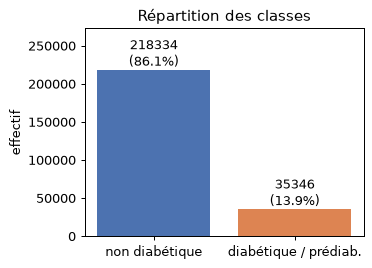

In [3]:
dup = df.duplicated(keep=False)
print(f"Part de positifs parmi les lignes dupliquées : {y[dup].mean():.1%}  |  parmi les autres : {y[~dup].mean():.1%}")
print("Profil le plus fréquent :")
display(df[df.duplicated(keep=False)].value_counts().head(1).reset_index().T)
mw.plot_class_balance(y, labels=("non diabétique", "diabétique / prédiab."));

Les doublons sont surtout des profils « sans aucun facteur de risque » (jeunes, en bonne santé),
avec très peu de positifs : c'est bien la signature de personnes différentes au profil banal.

Le classifieur trivial « personne n'est diabétique » a **86 % d'accuracy** et un rappel nul : ce
chiffre illustre pourquoi l'accuracy n'est pas la bonne métrique ici.

### Exploration rapide

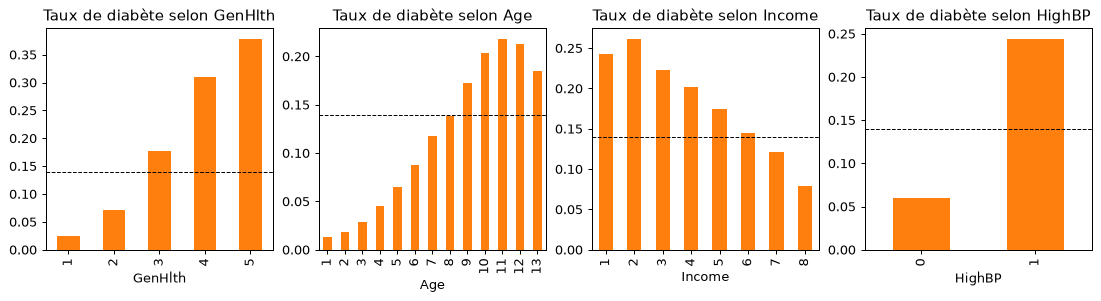

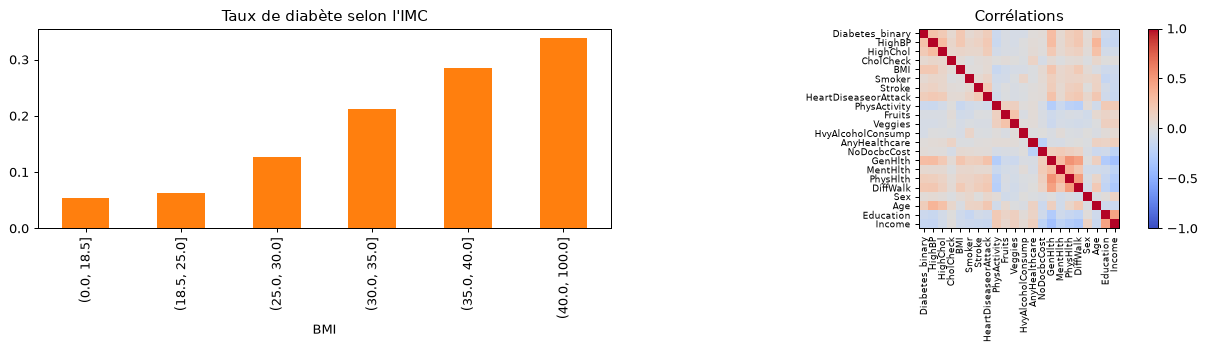

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2))
for ax, col in zip(axes, ["GenHlth", "Age", "Income", "HighBP"]):
    y.groupby(X[col]).mean().plot.bar(ax=ax, color="C1")
    ax.axhline(y.mean(), color="k", ls="--", lw=0.8)
    ax.set_title(f"Taux de diabète selon {col}")
bmi_bins = pd.cut(X["BMI"], [0, 18.5, 25, 30, 35, 40, 100])
fig2, ax2 = plt.subplots(1, 2, figsize=(14, 4))
y.groupby(bmi_bins, observed=True).mean().plot.bar(ax=ax2[0], color="C1", title="Taux de diabète selon l'IMC")
corr = df.corr()
im = ax2[1].imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax2[1].set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=7)
ax2[1].set_yticks(range(len(corr)), corr.columns, fontsize=7)
plt.colorbar(im, ax=ax2[1]); ax2[1].set_title("Corrélations")
plt.tight_layout()

Les effets sont nets et **monotones** : le taux de diabète passe d'environ 2 % (santé perçue
excellente) à près de 40 % (santé perçue mauvaise), croît avec l'âge et l'IMC, décroît avec le revenu.
Les variables sont modérément corrélées entre elles (GenHlth, PhysHlth, DiffWalk), et aucune
n'est corrélée à plus de 0,3 avec la cible : on s'attend à une tâche **difficile**, où aucun
modèle ne sépare parfaitement les classes (des informations clés, comme la glycémie, manquent).

## 2. Séparation train / test

Séparation **stratifiée** 80 / 20 (14 % de positifs des deux côtés). Le test n'est utilisé qu'à la
section 8. Tous les choix sont faits par validation croisée stratifiée sur le train.

In [5]:
X_train, X_test, y_train, y_test = mw.split_data(X, y, test_size=0.2, seed=SEED)
cv5, cv3 = mw.make_cv(5, SEED), mw.make_cv(3, SEED)
print(f"train : {X_train.shape}, {y_train.mean():.4f} de positifs | test : {X_test.shape}, {y_test.mean():.4f} de positifs")

SCORING = {
    "auc_pr": "average_precision",
    "auc_roc": "roc_auc",
    "acc_equilibree": "balanced_accuracy",
    "rappel": "recall",
    "precision": "precision",
    "f1": "f1",
}

train : (202944, 21), 0.1393 de positifs | test : (50736, 21), 0.1393 de positifs


## 3. Prétraitement

- **Centrage-réduction** (`StandardScalerManual`, appris sur le train) : nécessaire pour la régression
  logistique régularisée, le kNN, le SVM et le MLP, car BMI (12 à 98) et les variables binaires n'ont pas
  la même échelle. Inutile pour les arbres, mais sans effet néfaste ; on garde le même pipeline pour tous.
- **Pas de transformation log** : les variables ne sont pas à queue lourde comme sur Spambase.
- **ACP** : la question est de savoir si elle a un sens sur des variables majoritairement binaires.

,PC1,PC2
GenHlth,0.4050,-0.0290
DiffWalk,0.3586,0.0160
PhysHlth,0.3440,-0.0762
Income,-0.3212,0.1904
Education,-0.2584,0.1495
HighBP,0.2565,0.3221
PhysActivity,-0.2371,0.0834
MentHlth,0.2232,-0.2527


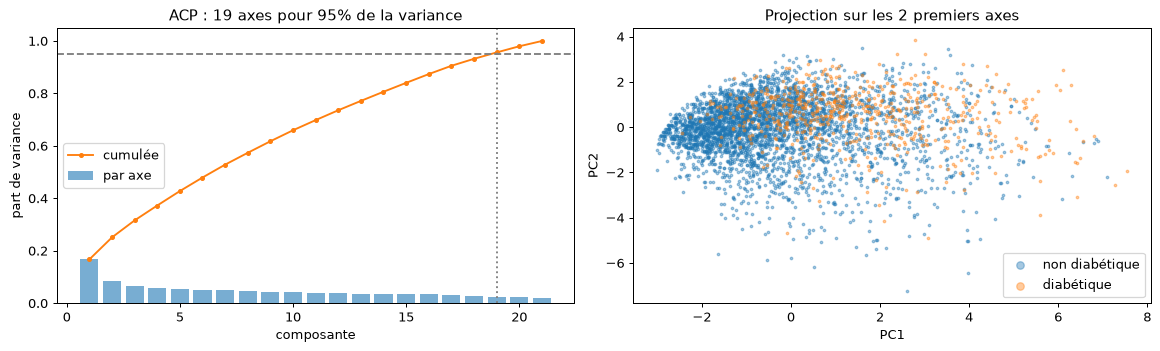

In [6]:
prep = mw.build_pipeline(None)                 # imputation -> centrage-réduction
Z_train = prep.fit_transform(X_train)
pca = mw.PCAManual(n_components=0.95).fit(Z_train)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
mw.plot_pca_variance(pca, 0.95, ax=axes[0])
mw.plot_pca_2d(pca.transform(Z_train), y_train, labels=("non diabétique", "diabétique"), ax=axes[1])
plt.tight_layout()
loadings = pd.DataFrame(pca.components_[:2].T, index=X.columns, columns=["PC1", "PC2"])
loadings.reindex(loadings["PC1"].abs().sort_values(ascending=False).index).head(8)

- **Il faut 19 axes sur 21 pour garder 95 % de la variance** : l'ACP ne comprime presque rien.
  Les variables, surtout binaires, sont peu corrélées linéairement entre elles.
- Le premier axe (16 % de la variance) a pourtant un sens : il oppose une **mauvaise santé générale**
  (GenHlth, DiffWalk, PhysHlth, HighBP élevés) à un **statut socio-économique élevé** (Income, Education,
  activité physique). Les diabétiques sont décalés vers la droite de cet axe, avec un fort recouvrement.
- Réserve de principe : l'ACP maximise une variance, notion naturelle pour des variables continues ;
  pour une variable binaire, la variance $p(1-p)$ ne mesure que le déséquilibre entre 0 et 1. Les axes
  restent calculables, mais leur interprétation est plus fragile. Son effet sur la classification est mesuré en 6.3.

<!-- P12 · Lucas : sections 4 à 8 (modèles, coût, biais/variance, réglage, sélection, déséquilibre, seuil, test) -->
## 4. Comparaison des modèles

Les modèles sont ceux du notebook Spambase (mêmes fonctions). Pour les comparer **à armes égales,
indépendamment du seuil**, on utilise l'AUC-PR et l'AUC-ROC et on n'applique **aucun traitement du
déséquilibre** ici (il fait l'objet de la section 7). Validation croisée 5 plis sur 203 000 lignes.

kNN et SVM à noyau sont exclus de cette comparaison pour une raison de coût, vérifiée juste après.

In [7]:
models = mw.get_models(SEED)
models["Random Forest"].set_params(n_estimators=150, min_samples_leaf=20)   # feuilles plus grosses : 200 000 lignes
names = ["Dummy (classe majoritaire)", "Régression logistique (GD, à la main)", "LDA (à la main)", "QDA (à la main)",
         "Bayes naïf gaussien", "Arbre de décision", "Random Forest", "Gradient Boosting (hist.)", "MLP (1 couche cachée)"]
res = mw.cross_validate_models({k: mw.build_pipeline(models[k]) for k in names}, X_train, y_train, SCORING, cv5)
res[["auc_pr_moy", "auc_pr_std", "auc_roc_moy", "acc_equilibree_moy", "rappel_moy", "precision_moy",
     "auc_pr_train", "temps_fit_s"]]

Dummy (classe majoritaire)                 auc_pr = 0.1393 ± 0.0000   (1.6 s)


Régression logistique (GD, à la main)      auc_pr = 0.4076 ± 0.0044   (1.7 s)


LDA (à la main)                            auc_pr = 0.4037 ± 0.0038   (1.4 s)


QDA (à la main)                            auc_pr = 0.3293 ± 0.0027   (1.6 s)


Bayes naïf gaussien                        auc_pr = 0.3419 ± 0.0022   (1.5 s)


Arbre de décision                          auc_pr = 0.4042 ± 0.0058   (0.7 s)


Random Forest                              auc_pr = 0.4316 ± 0.0064   (5.7 s)


Gradient Boosting (hist.)                  auc_pr = 0.4349 ± 0.0072   (4.3 s)


MLP (1 couche cachée)                      auc_pr = 0.4308 ± 0.0058   (2.6 s)


,auc_pr_moy,auc_pr_std,auc_roc_moy,acc_equilibree_moy,rappel_moy,precision_moy,auc_pr_train,temps_fit_s
modele,,,,,,,,
Gradient Boosting (hist.),0.4349,7.1790e-03,0.8301,0.5713,0.1609,0.5863,0.4597,1.9656
Random Forest,0.4316,6.3560e-03,0.8276,0.5509,0.1134,0.6104,0.5167,3.5762
MLP (1 couche cachée),0.4308,5.7881e-03,0.8292,0.5676,0.1531,0.5796,0.4402,1.9560
"Régression logistique (GD, à la main)",0.4076,4.3509e-03,0.8228,0.5681,0.1581,0.5389,0.4077,0.4576
Arbre de décision,0.4042,5.7779e-03,0.8172,0.5599,0.1377,0.5555,0.4226,0.3304
LDA (à la main),0.4037,3.8205e-03,0.8200,0.5876,0.2072,0.5121,0.4038,0.1499
Bayes naïf gaussien,0.3419,2.2043e-03,0.7848,0.6891,0.5720,0.3234,0.3419,0.1632
QDA (à la main),0.3293,2.7272e-03,0.7833,0.6715,0.5114,0.3296,0.3300,0.1495
Dummy (classe majoritaire),0.1393,1.1577e-05,0.5000,0.5000,0.0000,0.0000,0.1393,0.1573


Lecture du tableau (5 plis ; un pli de validation contient 40 000 personnes, d'où des écarts-types faibles, de l'ordre de 0,005) :

- **Référence** : l'AUC-PR d'un classement au hasard vaut la proportion de positifs, **0,139**.
  Les meilleurs modèles la triplent (≈ 0,43), avec une AUC-ROC de 0,83. C'est utile mais loin d'une
  séparation parfaite : l'enquête ne contient ni glycémie ni antécédents familiaux, et beaucoup de
  diabétiques ont un profil déclaré semblable à celui de non-diabétiques.
- **Gradient Boosting (0,435), Random Forest (0,432) et MLP (0,431) sont à égalité** (écarts inférieurs à un
  écart-type). La **régression logistique** (0,408), l'arbre seul et la **LDA** (0,404) sont environ 0,027 en
  dessous, soit 4 écarts-types : les non-linéarités et interactions apportent un gain réel mais modeste.
- **LDA ≈ régression logistique** : même frontière linéaire, et ici l'hypothèse gaussienne de la LDA coûte peu.
  **QDA et Bayes naïf** sont nettement moins bons (0,33–0,34) : covariance par classe ou indépendance
  conditionnelle sont des hypothèses fausses pour des variables binaires corrélées (HighBP et HighChol, GenHlth et PhysHlth).
- **Les métriques au seuil 0,5 sont trompeuses** : le boosting ne détecte que **16 %** des diabétiques au seuil 0,5,
  alors qu'il classe le mieux. QDA et Bayes naïf ont un meilleur rappel (51–57 %) uniquement parce que leurs
  probabilités sont mal calibrées (trop élevées), pas parce qu'ils sont meilleurs. Le seuil sera traité à part (sections 7–8).
- **Sur-apprentissage** : la forêt a une AUC-PR de 0,517 en entraînement contre 0,432 en validation (arbres profonds
  qui mémorisent) ; le boosting 0,460 contre 0,435 ; la régression logistique aucun écart (modèle simple, beaucoup de données).
- **Temps** : boosting ≈ 2,6 s par entraînement, forêt ≈ 13 s, régression logistique codée à la main ≈ 1,4 s.

### 4.1 Pourquoi pas de SVM à noyau ni de kNN sur 200 000 lignes ?

Temps d'entraînement et de prédiction (sur 5 000 points) mesurés sur des sous-échantillons de taille croissante.

In [8]:
expensive = {
    "SVM RBF": mw.build_pipeline(models["SVM RBF"]),
    "kNN": mw.build_pipeline(models["kNN"]),
    "Régression logistique (GD)": mw.build_pipeline(models["Régression logistique (GD, à la main)"]),
}
timing = mw.fit_time_scaling(expensive, X_train, y_train, sizes=[2500, 5000, 10000, 20000], seed=SEED)
display(timing.pivot(index="n_train", columns="modele", values=["fit_s", "predict_5000_s"]).round(3))

sub = np.random.default_rng(SEED).choice(len(X_train), 20000, replace=False)
res_sub = mw.cross_validate_models(
    {k: mw.build_pipeline(models[k]) for k in ["SVM RBF", "kNN", "Régression logistique (GD, à la main)", "Gradient Boosting (hist.)"]},
    X_train.iloc[sub], y_train.iloc[sub], {"auc_roc": "roc_auc", "acc_equilibree": "balanced_accuracy"}, cv3, verbose=False)
res_sub[["auc_roc_moy", "auc_roc_std", "temps_fit_s", "temps_predict_s"]]

fit_s                            predict_5000_s               
modele  Régression logistique (GD) SVM RBF    kNN Régression logistique (GD) SVM RBF    kNN
n_train                                                                                    
2500                         0.009   0.039  0.003                      0.001   0.110  0.015
5000                         0.013   0.131  0.005                      0.001   0.199  0.016
10000                        0.028   0.596  0.009                      0.001   0.355  0.022
20000                        0.043   2.253  0.018                      0.001   0.724  0.032

,auc_roc_moy,auc_roc_std,temps_fit_s,temps_predict_s
modele,,,,
"Régression logistique (GD, à la main)",0.8248,0.0068,0.0311,0.0050
Gradient Boosting (hist.),0.8219,0.0068,0.1413,0.0239
kNN,0.7778,0.0138,0.0137,0.3452
SVM RBF,0.7064,0.0083,1.0960,1.4623


- **SVM RBF** : doubler les données de 10 000 à 20 000 multiplie le temps d'entraînement par environ 5
  (1,5 s → 7,5 s), soit une croissance proche de $n^{2,3}$ : il faut construire et résoudre un problème
  dual dont la taille dépend des paires de points. Extrapolé à 200 000 lignes, cela donne de l'ordre de
  25 minutes **par entraînement**, à multiplier par le nombre de plis et de combinaisons d'hyperparamètres.
  La prédiction est aussi lente (elle coûte un noyau par vecteur de support). Et sur 20 000 lignes, il est
  **moins bon** que la régression logistique (AUC 0,71 contre 0,82, sans réglage).
- **kNN** : l'entraînement est instantané (on stocke les données), mais la prédiction croît linéairement
  avec $n$. Sur 200 000 lignes elle resterait faisable ; c'est surtout sa **performance** qui l'exclut (AUC 0,78) :
  la distance euclidienne entre profils faits de variables binaires et ordinales produit énormément d'ex æquo
  et n'a pas de sens métier.
- La régression logistique, entraînée sur 20 000 lignes seulement, fait déjà aussi bien que le boosting
  (0,825 contre 0,822) : le boosting a besoin de beaucoup de données pour exploiter les interactions.

### 4.2 Biais ou variance ? Courbe d'apprentissage et courbe de validation

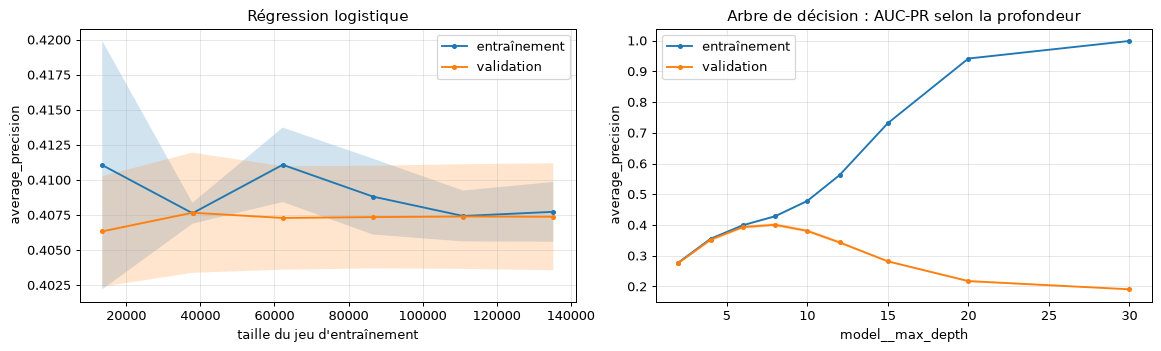

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
mw.plot_learning_curve(mw.build_pipeline(models["Régression logistique (GD, à la main)"]), X_train, y_train,
                       "average_precision", cv3, ax=axes[0], title="Régression logistique")
mw.plot_validation_curve(mw.build_pipeline(mw.clone(models["Arbre de décision"]).set_params(min_samples_leaf=1)),
                         X_train, y_train, "model__max_depth", [2, 4, 6, 8, 10, 12, 15, 20, 30],
                         "average_precision", cv3, ax=axes[1])
axes[1].set_title("Arbre de décision : AUC-PR selon la profondeur")
plt.tight_layout()

- **Régression logistique** : les scores d'entraînement et de validation sont confondus (≈ 0,407) dès 15 000
  lignes et ne bougent plus. Le modèle est **limité par son biais** (frontière linéaire) : 10 fois plus de
  données ne l'amélioreraient pas. Pour progresser, il faut un modèle plus riche ou de meilleures variables.
- **Arbre de décision** : l'AUC-PR d'entraînement tend vers 1 quand la profondeur augmente, alors que la
  validation culmine vers une profondeur de **8** (≈ 0,40) puis s'effondre (0,19 à profondeur 30). C'est le
  sur-apprentissage typique : l'arbre profond découpe l'espace jusqu'à isoler des individus. La profondeur
  8 utilisée par défaut est au bon endroit.

## 5. Réglage des hyperparamètres

Régression logistique (grille sur $C$) et Gradient Boosting (tirage aléatoire de 12 combinaisons),
critère AUC-PR, validation croisée 3 plis (203 000 lignes : 3 plis suffisent, l'écart-type entre plis est faible).

In [10]:
best_lr, tab_lr = mw.tune_model(mw.build_pipeline(models["Régression logistique (GD, à la main)"]),
                                {"model__C": [1e-4, 1e-3, 1e-2, 1e-1, 1, 10]}, X_train, y_train, "average_precision", cv3)
display(tab_lr)
best_gb, tab_gb = mw.tune_model(mw.build_pipeline(models["Gradient Boosting (hist.)"]),
                                {"model__learning_rate": [0.03, 0.05, 0.1, 0.2],
                                 "model__max_leaf_nodes": [7, 15, 31, 63],
                                 "model__min_samples_leaf": [20, 100, 400],
                                 "model__l2_regularization": [0.0, 1.0, 10.0],
                                 "model__max_iter": [1000]},
                                X_train, y_train, "average_precision", cv3, n_iter=12, seed=SEED)
tab_gb.head(5)

,C,mean_test_score,std_test_score
0,0.0010,0.4079,0.0037
1,0.0100,0.4075,0.0038
2,0.1000,0.4074,0.0038
3,1.0000,0.4074,0.0038
4,10.0000,0.4074,0.0038
5,0.0001,0.4039,0.0033


,min_samples_leaf,max_leaf_nodes,max_iter,learning_rate,l2_regularization,mean_test_score,std_test_score
0,400,15,1000,0.05,1.0,0.4352,0.0080
1,400,31,1000,0.03,1.0,0.4351,0.0076
2,100,31,1000,0.05,0.0,0.4349,0.0073
3,20,63,1000,0.05,10.0,0.4348,0.0068
4,20,31,1000,0.05,0.0,0.4347,0.0074


- **La régression logistique est insensible à $C$** (AUC-PR entre 0,4074 et 0,4079 de $C=10^{-3}$ à $10$) :
  avec 200 000 lignes pour 21 coefficients, la vraisemblance domine la pénalité, qui n'a presque rien à corriger.
- **Le boosting est sur un plateau** : les 12 combinaisons tirées donnent toutes entre 0,433 et 0,435. Le
  meilleur réglage (taux d'apprentissage 0,05, 15 feuilles, au moins 400 individus par feuille) privilégie
  des arbres simples et beaucoup d'itérations, mais le gain sur les valeurs par défaut est négligeable.
- Conclusion : sur ce jeu, **les performances sont limitées par l'information contenue dans les données**,
  pas par les hyperparamètres.

## 6. Sélection de variables

### 6.1 Classement par quatre critères

,anova_F,info_mutuelle,abs_coef_L1,permutation_RF,rang_moyen
GenHlth,2882.4402,0.0487,0.5697,0.0416,1.00
BMI,1586.6642,0.0266,0.4227,0.0415,2.50
HighBP,2170.4250,0.0378,0.3669,0.0233,2.75
HighChol,1165.0769,0.0190,0.2543,0.0097,5.00
Age,964.3748,0.0176,0.3739,0.0215,5.00
Income,913.8453,0.0143,0.1181,0.0023,7.75
HeartDiseaseorAttack,1044.7581,0.0103,0.0873,0.0040,8.00
DiffWalk,1426.3711,0.0189,0.0119,0.0028,8.50
Education,547.2121,0.0104,0.0547,0.0015,10.50
PhysHlth,909.4051,0.0106,0.0458,0.0015,10.50


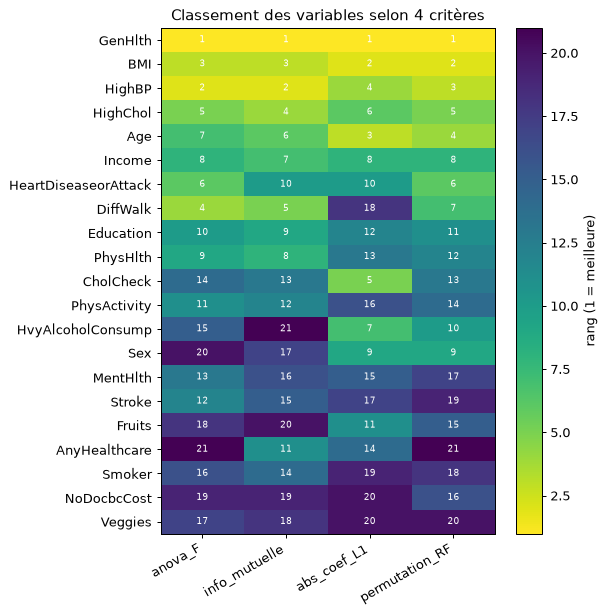

In [11]:
ranking = mw.rank_features(X_train, y_train, seed=SEED, n_perm_samples=30000)
mw.plot_feature_ranking(ranking, top=21)
ranking[["anova_F", "info_mutuelle", "abs_coef_L1", "permutation_RF", "rang_moyen"]].round(4)

- **Les quatre critères s'accordent** sur les variables principales : **GenHlth** (santé perçue, 1re partout),
  **BMI**, **HighBP**, **Age**, **HighChol**. Ce sont les facteurs de risque connus du diabète de type 2.
- **Désaccords instructifs** :
  - **DiffWalk** est 4e pour l'ANOVA mais 18e pour la L1 : prise seule, la difficulté à marcher est très liée
    au diabète, mais cette information est **redondante** avec GenHlth et PhysHlth. Le modèle multivarié n'en a plus besoin.
  - **CholCheck** (avoir fait un contrôle de cholestérol dans les 5 ans), **HvyAlcoholConsump** et **Sex** sont
    mal classées par les filtres mais bien placées par la L1. Leur effet n'apparaît **qu'à profil égal** :
    par exemple, à âge, IMC et tension égaux, ne jamais avoir contrôlé son cholestérol est associé à moins de
    diagnostics (et sans doute à moins de dépistage). Un filtre univarié ne peut pas voir ces effets conditionnels.
- Les variables les moins utiles sont les mêmes pour tous les critères : Smoker, Veggies, NoDocbcCost, Fruits, AnyHealthcare.

### 6.2 Score en fonction du nombre de variables (filtre ANOVA dans le pipeline) et wrapper RFE

RFECV (régression logistique) garde 18 variables ; écartées : ['Smoker', 'Veggies', 'NoDocbcCost']


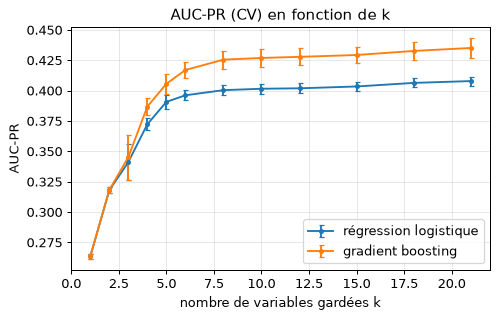

In [12]:
from sklearn.feature_selection import SelectKBest, f_classif, RFECV
from sklearn.linear_model import LogisticRegression
lr_model, gb_model = best_lr.named_steps["model"], best_gb.named_steps["model"]
ks = [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 18, 21]
curve_lr = mw.cv_score_vs_k(lambda k: mw.build_pipeline(lr_model, selector=SelectKBest(f_classif, k=k)),
                            X_train, y_train, ks, "average_precision", cv3)
curve_gb = mw.cv_score_vs_k(lambda k: mw.build_pipeline(gb_model, selector=SelectKBest(f_classif, k=k)),
                            X_train, y_train, ks, "average_precision", cv3)
ax = mw.plot_score_vs_k(curve_lr, "AUC-PR", label="régression logistique")
mw.plot_score_vs_k(curve_gb, "AUC-PR", ax=ax, label="gradient boosting")
ax.legend()

rfecv = RFECV(LogisticRegression(max_iter=2000), step=1, cv=cv3, scoring="average_precision", n_jobs=-1)
rfecv.fit(prep.fit_transform(X_train), y_train)       # exploratoire : on regarde quelles variables RFE garde
print(f"RFECV (régression logistique) garde {rfecv.n_features_} variables ; écartées :",
      list(X_train.columns[~rfecv.support_]))

- L'AUC-PR grimpe jusqu'à environ **8 variables**, puis n'augmente presque plus : GenHlth, HighBP, BMI,
  DiffWalk, HighChol, Age... portent l'essentiel de l'information. Avec les 10 meilleures, on perd 0,006
  (régression logistique) et 0,008 (boosting) d'AUC-PR.
- Le **wrapper RFECV** garde 18 variables sur 21 et écarte Smoker, Veggies et NoDocbcCost, exactement les
  variables jugées inutiles à la section 6.1.

### 6.3 Comparaison : toutes les variables, sous-ensemble sélectionné, ou ACP

In [13]:
variants = {
    "LR — 21 variables": best_lr,
    "LR — 10 meilleures (ANOVA)": mw.build_pipeline(lr_model, selector=SelectKBest(f_classif, k=10)),
    "LR — RFECV": mw.build_pipeline(lr_model, selector=RFECV(LogisticRegression(max_iter=2000), step=1, cv=mw.make_cv(3, SEED),
                                                             scoring="average_precision")),
    "LR — ACP 95 %": mw.build_pipeline(lr_model, pca=0.95),
    "GB — 21 variables": best_gb,
    "GB — 10 meilleures (ANOVA)": mw.build_pipeline(gb_model, selector=SelectKBest(f_classif, k=10)),
    "GB — ACP 95 %": mw.build_pipeline(gb_model, pca=0.95),
}
res_sel = mw.cross_validate_models(variants, X_train, y_train, {"auc_pr": "average_precision", "auc_roc": "roc_auc"},
                                   cv3, verbose=False)
res_sel[["auc_pr_moy", "auc_pr_std", "auc_roc_moy", "temps_fit_s"]].sort_index()

,auc_pr_moy,auc_pr_std,auc_roc_moy,temps_fit_s
modele,,,,
GB — 10 meilleures (ANOVA),0.4269,0.0076,0.8258,1.6865
GB — 21 variables,0.4352,0.0080,0.8306,3.8430
GB — ACP 95 %,0.4213,0.0050,0.8239,1.8829
LR — 10 meilleures (ANOVA),0.4016,0.0042,0.8185,0.2336
LR — 21 variables,0.4079,0.0037,0.8227,0.3182
LR — ACP 95 %,0.4011,0.0036,0.8165,0.3506
LR — RFECV,0.4079,0.0037,0.8228,1.8041


- **RFECV (18 variables) = 21 variables** (AUC-PR 0,4079 dans les deux cas) : trois variables sont inutiles
  et peuvent être retirées sans perte. C'est la sélection la plus intéressante : même performance, modèle plus simple.
- **10 variables (filtre ANOVA)** : perte faible (0,006 à 0,008), pour un modèle deux fois plus petit, et
  un temps d'entraînement divisé par deux pour le boosting.
- **ACP 95 % (19 composantes)** : pas de réduction utile, et une **perte** (boosting 0,435 → 0,421 ; régression
  logistique 0,408 → 0,401). Les arbres perdent les coupures naturelles sur les variables d'origine (« HighBP = 1 »,
  « GenHlth ≥ 4 »), et pour la régression logistique les deux composantes écartées portaient encore un peu
  d'information discriminante : l'ACP les juge sur leur variance, pas sur leur lien avec le label.

**Choix retenu** : toutes les variables pour le modèle final (la meilleure performance). Pour un déploiement réel
(questionnaire de dépistage), la version à 10 variables serait un compromis raisonnable : 11 questions de moins à poser
pour moins de 0,01 d'AUC-PR.

## 7. Traitement du déséquilibre

Mêmes modèles (régression logistique et Gradient Boosting réglés), six stratégies :
aucune (seuil 0,5), pondération des classes, sous-échantillonnage de la classe majoritaire,
SMOTE, seuil bayésien pour $c_{FN}/c_{FP}=5$ (on décide « diabétique » si $\hat p > 1/6$),
et seuil maximisant le F2 choisi par validation croisée interne. Le rééchantillonnage n'est appliqué
qu'aux plis d'entraînement (pipeline `imblearn`). Validation croisée 3 plis.

In [14]:
SCORING_IMB = {"f2": mw.fbeta_scorer(2),
               "rappel": "recall", "precision": "precision", "acc_equilibree": "balanced_accuracy",
               "auc_pr": "average_precision", "auc_roc": "roc_auc"}
tables = {}
for label, base in [("Régression logistique", lr_model), ("Gradient Boosting", gb_model)]:
    strategies = mw.imbalance_strategies(base, beta=2, cost_fn=5, cost_fp=1, seed=SEED)
    t = mw.cross_validate_models(strategies, X_train, y_train, SCORING_IMB, cv3, verbose=False)
    tables[label] = t[[f"{m}_moy" for m in SCORING_IMB] + ["temps_fit_s"]]
    print(label); display(tables[label])

Régression logistique


,f2_moy,rappel_moy,precision_moy,acc_equilibree_moy,auc_pr_moy,auc_roc_moy,temps_fit_s
modele,,,,,,,
seuil max F2 (CV interne),0.5999,0.8341,0.2827,0.7457,0.4079,0.8227,1.6678
sous-échantillonnage,0.5927,0.7630,0.3132,0.7461,0.4069,0.8230,0.1837
class_weight='balanced',0.5927,0.7648,0.3119,0.7458,0.4064,0.8233,0.3306
SMOTE,0.5917,0.7617,0.3126,0.7453,0.4044,0.8226,1.2538
seuil bayésien (c_FN/c_FP=5 → 0.167),0.5795,0.7108,0.3333,0.7403,0.4079,0.8227,0.3614
"aucun traitement (seuil 0,5)",0.1656,0.1410,0.5465,0.5610,0.4079,0.8227,0.3533


Gradient Boosting


,f2_moy,rappel_moy,precision_moy,acc_equilibree_moy,auc_pr_moy,auc_roc_moy,temps_fit_s
modele,,,,,,,
seuil max F2 (CV interne),0.6055,0.8284,0.2917,0.7513,0.4352,0.8306,11.9010
class_weight='balanced',0.6023,0.7932,0.3069,0.7516,0.4344,0.8305,3.6844
sous-échantillonnage,0.6021,0.7953,0.3053,0.7512,0.4308,0.8294,0.8251
seuil bayésien (c_FN/c_FP=5 → 0.167),0.5920,0.7372,0.3312,0.7481,0.4352,0.8306,3.8473
SMOTE,0.2247,0.1954,0.5622,0.5853,0.4322,0.8283,22.7333
"aucun traitement (seuil 0,5)",0.1945,0.1668,0.5812,0.5737,0.4352,0.8306,3.8408


Lecture :

- **Sans traitement, au seuil 0,5, le modèle est inutilisable pour le dépistage** : 14 à 17 % des diabétiques
  détectés. Le modèle minimise l'erreur totale, et comme 86 % des gens sont sains, il répond presque toujours « sain ».
- **Pondération des classes, sous-échantillonnage et changement de seuil donnent presque le même résultat**
  (rappel 71 à 83 %, F2 ≈ 0,58–0,61). Ce n'est pas un hasard : multiplier le poids des positifs par $w$ dans la
  log-vraisemblance revient, pour un modèle bien spécifié, à décaler le logit de $\log w$, c'est-à-dire à **déplacer
  le seuil**. Le classement des individus ne change pas, donc **l'AUC-PR et l'AUC-ROC restent identiques** (0,408 et
  0,823 pour la régression logistique dans les lignes à seuil). Le sous-échantillonnage perd un peu d'AUC (0,431 au lieu
  de 0,435 pour le boosting), car il jette 75 % des non-diabétiques.
- **Le meilleur F2** est obtenu en choisissant le seuil par validation croisée interne (0,600 et 0,606) : c'est la
  stratégie qui optimise directement le critère choisi. Le seuil bayésien (fixé par une hypothèse de coûts, 5:1) est
  un peu plus prudent (rappel 71–74 %, précision 33 %).
- **SMOTE fonctionne pour la régression logistique, mais échoue complètement avec le boosting** (rappel 20 %,
  à peine plus que sans traitement). Explication ci-dessous.

In [15]:
from imblearn.over_sampling import SMOTE
auc_syn = mw.synthetic_vs_real_auc(X_train, y_train, SMOTE(random_state=SEED), seed=SEED)
print(f"AUC d'un classifieur qui distingue vrais diabétiques et diabétiques synthétiques de SMOTE : {auc_syn:.3f}")

AUC d'un classifieur qui distingue vrais diabétiques et diabétiques synthétiques de SMOTE : 0.998


**Les points créés par SMOTE sont presque parfaitement reconnaissables.** SMOTE crée un point en interpolant entre un
diabétique et l'un de ses voisins : $x_{\text{new}} = x_i + u\,(x_j - x_i)$ avec $u \sim \mathcal U(0,1)$. Sur des
variables binaires ou entières, cela produit des valeurs impossibles (HighBP = 0,37, Age = 8,6, BMI = 27,3). Dans le
train rééchantillonné, « avoir une valeur non entière » devient donc un excellent prédicteur de la classe 1. Le
boosting, très flexible, l'apprend ; or **aucun vrai patient du test n'a de valeur non entière**, donc le modèle ne
les reconnaît plus comme diabétiques. La régression logistique, linéaire, ne peut pas exploiter cet artefact, d'où son
bon comportement. Une variante adaptée aux variables catégorielles (SMOTENC) limiterait le problème ; ici, le seuil
ajusté fait mieux sans fabriquer de données.

## 8. Modèle final, seuil, puis évaluation sur le test

### 8.1 Calibration des probabilités

Le seuil bayésien $c_{FP}/(c_{FP}+c_{FN})$ n'est optimal que si $\hat p(x)$ estime bien
$P(Y=1\mid x)$. On le vérifie sur des scores hors pli du train.

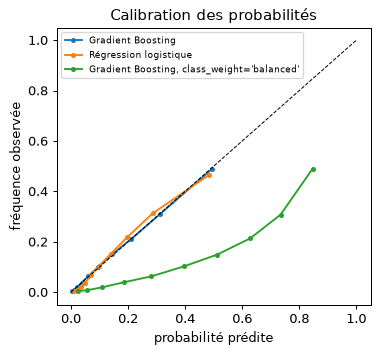

In [16]:
oof_gb = mw.out_of_fold_scores(best_gb, X_train, y_train, cv3)
oof_lr = mw.out_of_fold_scores(best_lr, X_train, y_train, cv3)
gb_bal = mw.clone(best_gb).set_params(model__class_weight="balanced")
oof_gb_bal = mw.out_of_fold_scores(gb_bal, X_train, y_train, cv3)
mw.plot_calibration({"Gradient Boosting": oof_gb, "Régression logistique": oof_lr,
                     "Gradient Boosting, class_weight='balanced'": oof_gb_bal}, y_train);

- Les probabilités du **boosting** et de la **régression logistique** (sans pondération) sont **bien calibrées** :
  les points suivent la diagonale. Le seuil bayésien $\hat p > 1/6$ a donc bien le sens voulu.
- Avec `class_weight='balanced'`, les probabilités sont **fortement surestimées** (prédit 0,8 pour une fréquence
  réelle de 0,3) : le modèle a appris sur une population fictive à 50 % de diabétiques. Pour l'utiliser avec un
  seuil bayésien, il faudrait d'abord corriger le décalage de prior
  (ramener les probabilités à la vraie proportion de 14 % de diabétiques).
  C'est un argument pour **garder le modèle non pondéré et agir sur le seuil** : on conserve des probabilités
  interprétables (« 23 % de risque ») en plus de la décision.

Modèle retenu : Gradient Boosting
Seuil max F2 (hors pli, train) : 0.118 | seuil bayésien (c_FN = 5 c_FP) : 0.167


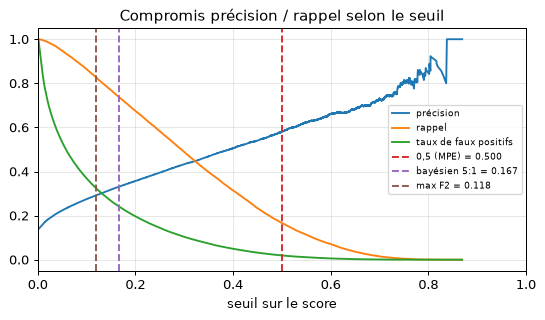

In [17]:
# choix par validation croisée (section 5) : meilleure AUC-PR moyenne
FINAL_NAME = "Gradient Boosting" if tab_gb.loc[0, "mean_test_score"] > tab_lr.loc[0, "mean_test_score"] else "Régression logistique"
print("Modèle retenu :", FINAL_NAME)
final_model = best_gb if FINAL_NAME == "Gradient Boosting" else best_lr
oof = oof_gb if FINAL_NAME == "Gradient Boosting" else oof_lr
thr_f2 = mw.fbeta_threshold(y_train, oof, beta=2)
thr_bayes = mw.bayes_risk_threshold(cost_fn=5, cost_fp=1)
print(f"Seuil max F2 (hors pli, train) : {thr_f2:.3f} | seuil bayésien (c_FN = 5 c_FP) : {thr_bayes:.3f}")
mw.plot_threshold_tradeoff(y_train, oof, {"0,5 (MPE)": 0.5, "bayésien 5:1": thr_bayes, "max F2": thr_f2});

### 8.2 Évaluation finale (le test n'est utilisé qu'ici)

,auc_pr,auc_roc,accuracy,accuracy_equilibree,rappel,precision,specificite,f2,VP,FN,FP
"seuil 0,5 = 0.500",0.4234,0.8272,0.8652,0.5707,0.1624,0.5557,0.9790,0.1892,1148.0,5921.0,918.0
seuil bayésien = 0.167,0.4234,0.8272,0.7567,0.7488,0.7379,0.3321,0.7598,0.5930,5216.0,1853.0,10490.0
seuil F2 = 0.118,0.4234,0.8272,0.6934,0.7512,0.8312,0.2903,0.6711,0.6056,5876.0,1193.0,14362.0


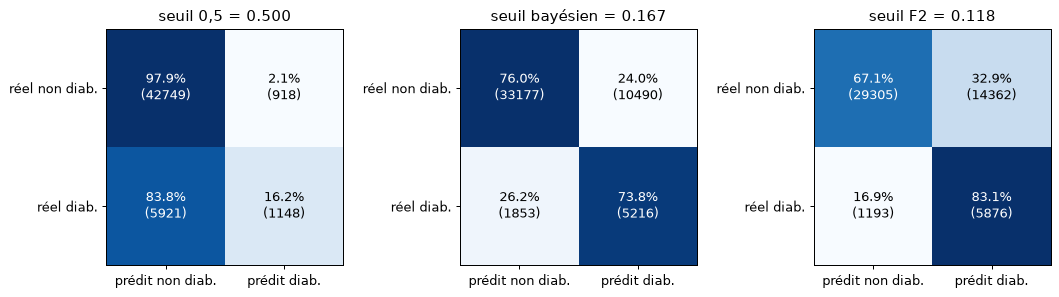

In [18]:
final_model.fit(X_train, y_train)
results = {f"seuil {name} = {t:.3f}": mw.evaluate_on_test(final_model, X_test, y_test, threshold=t, beta=2)
           for name, t in [("0,5", 0.5), ("bayésien", thr_bayes), ("F2", thr_f2)]}
cols = ["auc_pr", "auc_roc", "accuracy", "accuracy_equilibree", "rappel", "precision", "specificite", "f2", "VP", "FN", "FP"]
display(mw.results_table(results, cols))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, (name, m) in zip(axes, results.items()):
    mw.plot_confusion(m, ("non diab.", "diab."), normalize=True, ax=ax, title=name)
plt.tight_layout()

- **Seuil 0,5** : 86,5 % d'accuracy, à peine plus que le classifieur trivial (86,1 %), et seulement **16 %** des
  diabétiques détectés. Démonstration directe que l'accuracy ne convient pas à ce problème.
- **Seuil F2 (0,118, choisi sur le train)** : **83 % des diabétiques détectés** (5 876 sur 7 069), précision 29 %,
  spécificité 67 %. Parmi les personnes signalées, 29 % sont diabétiques, contre 14 % dans la population : le
  modèle double la « rentabilité » du dépistage tout en ne manquant qu'un diabétique sur six. Le prix : un tiers des
  personnes saines sont orientées vers un test.
- **Seuil bayésien (0,167)** : compromis intermédiaire, 74 % de rappel, 24 % de faux positifs.
- AUC-PR 0,423 et AUC-ROC 0,827 sur le test, contre 0,435 et 0,831 en validation croisée : légèrement en dessous,
  dans la fourchette de variabilité observée entre plis (± 0,008). Pas de signe de sur-apprentissage des choix.

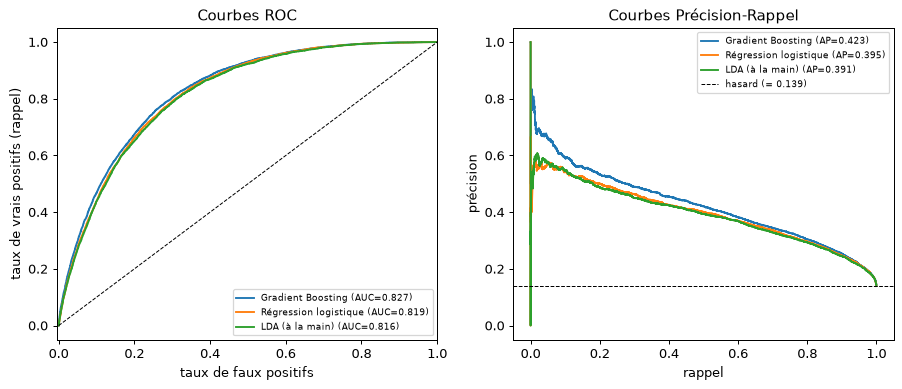

In [19]:
final_lr = mw.clone(best_lr).fit(X_train, y_train)
lda_pipe = mw.build_pipeline(mw.GaussianBayesClassifier("shared", reg=1e-3)).fit(X_train, y_train)
scores = {"Gradient Boosting": mw.get_scores(best_gb.fit(X_train, y_train), X_test),
          "Régression logistique": mw.get_scores(final_lr, X_test),
          "LDA (à la main)": mw.get_scores(lda_pipe, X_test)}
mw.plot_roc_pr(scores, y_test);

(Ces courbes de test n'ont servi à aucun choix : elles situent le modèle retenu par rapport aux deux suivants.)